In [4]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [6]:
data = sns.load_dataset('tips')
data.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
tips = data['tip'].values # extrai os dados da coluna tip

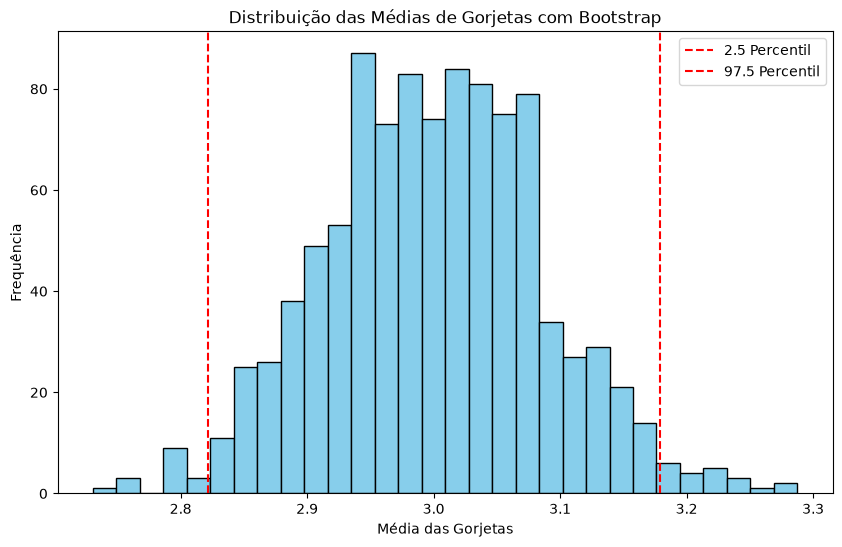

In [ ]:
# Número de reamostragens bootstrap
n_resamples = 1000

# Executa o bootstrap do SciPy: calcula a média (np.mean) de 1000 reamostras de "tips"
# e monta o IC de 95% pelo método percentil (limites em 2,5% e 97,5%)
# (tips vai dentro de uma tupla, formato exigido pelo SciPy)
ci = bootstrap((tips,), np.mean, confidence_level=0.95, n_resamples=n_resamples, method='percentile')

# Extrai o intervalo de confiança do resultado (objeto com .low e .high)
confidence_interval = ci.confidence_interval

# Mostra o intervalo na saída da célula
confidence_interval

# Cria a figura (10 de largura x 6 de altura)
plt.figure(figsize=(10, 6))

# Histograma das médias bootstrap (30 barras, azul-claro, contorno preto)
plt.hist(bootstrap_means, bins=30, color='skyblue', edgecolor='black')

# Linha vermelha tracejada no limite inferior do IC
plt.axvline(confidence_interval.low, color='red', linestyle='--', label='2.5 Percentil')

# Linha vermelha tracejada no limite superior do IC
plt.axvline(confidence_interval.high, color='red', linestyle='--', label='97.5 Percentil')

# Rótulo do eixo X: média de cada reamostra
plt.xlabel('Média das Gorjetas')

# Rótulo do eixo Y: quantas reamostras caíram em cada barra
plt.ylabel('Frequência')

# Título do gráfico
plt.title('Distribuição das Médias de Gorjetas com Bootstrap')

# Exibe a legenda com os textos de "label"
plt.legend()

# Mostra o gráfico
plt.show()